# 01 - Exploratory Data Analysis
**Plant disease classification** (Healthy / Powdery / Rust)

Goals:
1. Understand the class distribution per split
2. Look at sample images
3. Check image sizes and aspect ratios
4. Compare brightness/contrast across classes
5. Detect corrupted images and duplicates (train/test leakage)
6. Turn findings into preprocessing decisions

In [ ]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, UnidentifiedImageError

sns.set_theme(style="whitegrid")

DATA_DIR = Path("../data/raw")
SPLITS = ["Train", "Validation", "Test"]
CLASSES = ["Healthy", "Powdery", "Rust"]
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

## 1. Build an inventory of all images

In [ ]:
records = []
for split in SPLITS:
    for cls in CLASSES:
        for p in (DATA_DIR / split / cls).rglob("*"):
            if p.suffix.lower() in EXTS:
                records.append({"path": p, "split": split, "label": cls})

df = pd.DataFrame(records)
print(f"Total images: {len(df)}")
df.head()

Total images: 1532


,path,split,label
0,..\data\raw\Train\Healthy\800edef467d27c15.jpg,Train,Healthy
1,..\data\raw\Train\Healthy\801d6dcd96e48ebc.jpg,Train,Healthy
2,..\data\raw\Train\Healthy\802b59956a7aa5e7.jpg,Train,Healthy
3,..\data\raw\Train\Healthy\803bcb65f486e39a.jpg,Train,Healthy
4,..\data\raw\Train\Healthy\803e60cf3c64e1fe.jpg,Train,Healthy


## 2. Class distribution per split

label,Healthy,Powdery,Rust
split,,,
Train,458,430,434
Validation,20,20,20
Test,50,50,50


label,Healthy,Powdery,Rust
split,,,
Train,34.6,32.5,32.8
Validation,33.3,33.3,33.3
Test,33.3,33.3,33.3


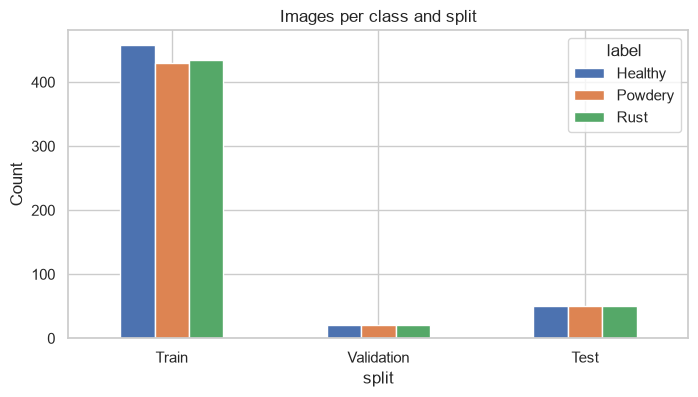

In [ ]:
counts = df.groupby(["split", "label"]).size().unstack(fill_value=0).loc[SPLITS]
display(counts)
display((counts.div(counts.sum(axis=1), axis=0) * 100).round(1))

counts.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Images per class and split")
plt.ylabel("Count")
plt.show()

## 3. Sample images

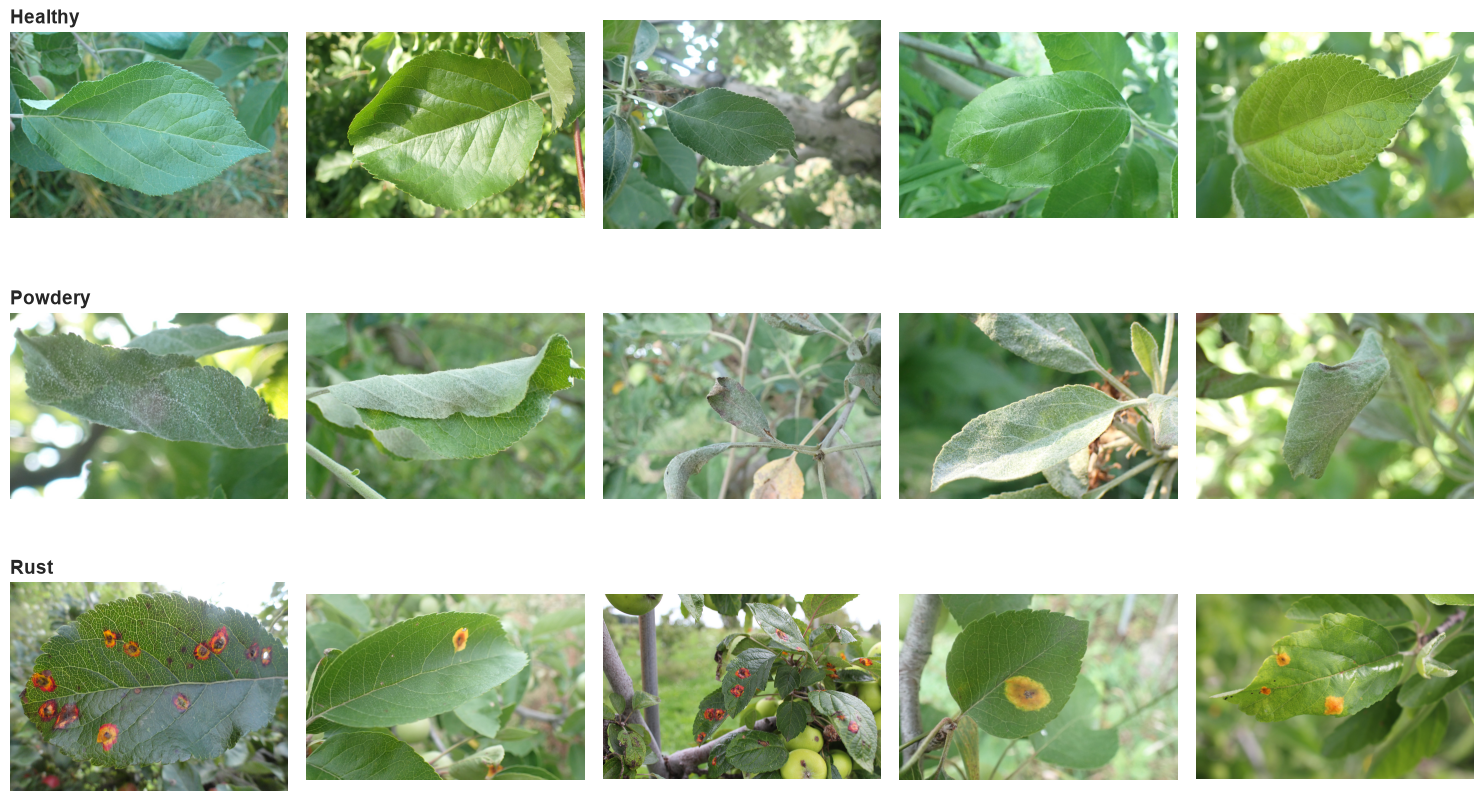

In [ ]:
def show_samples(n=5, seed=42):
    fig, axes = plt.subplots(len(CLASSES), n, figsize=(3 * n, 3 * len(CLASSES)))
    for i, cls in enumerate(CLASSES):
        sample = df[(df.label == cls) & (df.split == "Train")].sample(n, random_state=seed)
        for j, path in enumerate(sample.path):
            axes[i, j].imshow(Image.open(path).convert("RGB"))
            axes[i, j].axis("off")
            if j == 0:
                axes[i, j].set_title(cls, loc="left", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

show_samples()

## 4. Image sizes, aspect ratios, and corrupted files

In [ ]:
widths, heights, modes, corrupted = [], [], [], []
for p in df.path:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = im.size
            widths.append(w); heights.append(h); modes.append(im.mode)
    except (UnidentifiedImageError, OSError) as e:
        corrupted.append(p)
        widths.append(None); heights.append(None); modes.append(None)

df["width"], df["height"], df["mode"] = widths, heights, modes
df["aspect"] = df.width / df.height
print(f"Corrupted/unreadable images: {len(corrupted)}")
print("\nColor modes:\n", df["mode"].value_counts(dropna=False))
display(df[["width", "height", "aspect"]].describe().round(2))

Corrupted/unreadable images: 0

Color modes:
 mode
RGB    1532
Name: count, dtype: int64


,width,height,aspect
count,1532.00,1532.00,1532.00
mean,3986.06,2702.45,1.48
std,521.64,385.26,0.05
min,2421.00,1728.00,1.06
25%,4000.00,2672.00,1.50
50%,4000.00,2672.00,1.50
75%,4000.00,2672.00,1.50
max,5184.00,3456.00,1.50


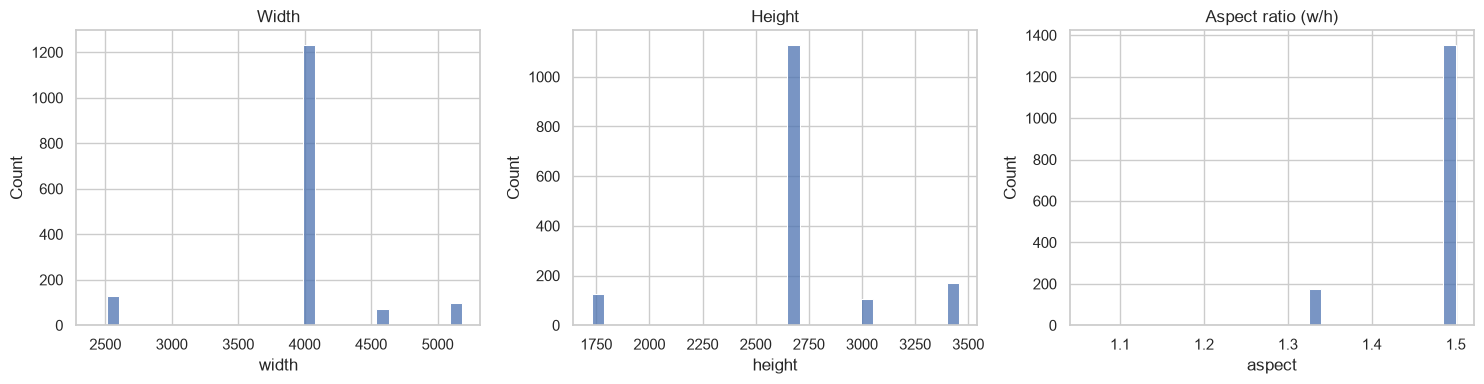

Unique sizes: 8


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.width.dropna(), ax=axes[0], bins=30); axes[0].set_title("Width")
sns.histplot(df.height.dropna(), ax=axes[1], bins=30); axes[1].set_title("Height")
sns.histplot(df.aspect.dropna(), ax=axes[2], bins=30); axes[2].set_title("Aspect ratio (w/h)")
plt.tight_layout()
plt.show()

print("Unique sizes:", df[["width", "height"]].drop_duplicates().shape[0])

## 5. Brightness and contrast per class
Computed on a downscaled grayscale version for speed.

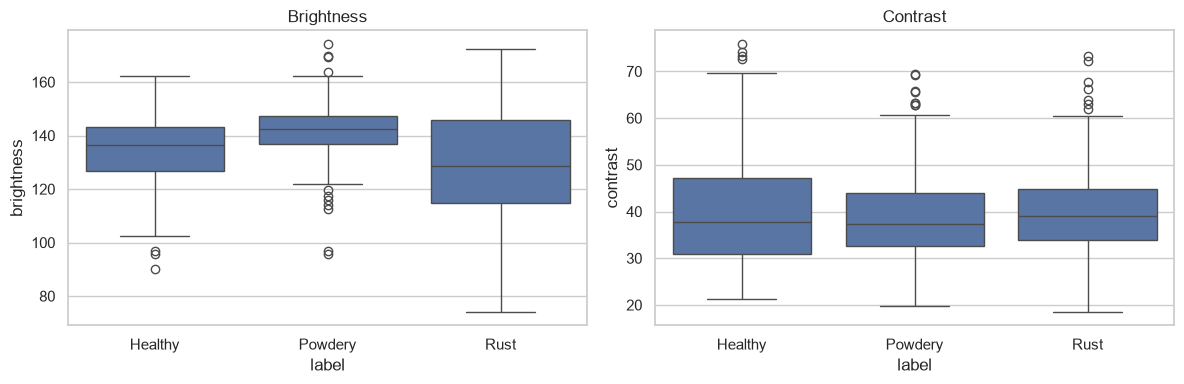

In [ ]:
def brightness_contrast(path, size=128):
    with Image.open(path) as im:
        arr = np.asarray(im.convert("L").resize((size, size)), dtype=np.float32)
    return arr.mean(), arr.std()

valid = df[df.width.notna()].copy()
stats = valid.path.apply(brightness_contrast)
valid["brightness"] = stats.apply(lambda x: x[0])
valid["contrast"] = stats.apply(lambda x: x[1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=valid, x="label", y="brightness", ax=axes[0]); axes[0].set_title("Brightness")
sns.boxplot(data=valid, x="label", y="contrast", ax=axes[1]); axes[1].set_title("Contrast")
plt.tight_layout()
plt.show()

## 6. Duplicates and train/val/test leakage
Exact duplicates are detected with an MD5 hash of the file bytes.

In [ ]:
def md5(path):
    return hashlib.md5(path.read_bytes()).hexdigest()

df["hash"] = df.path.apply(md5)
dup = df[df.duplicated("hash", keep=False)].sort_values("hash")
print(f"Images involved in exact duplicates: {len(dup)}")

leak = (
    df.groupby("hash")["split"].nunique().loc[lambda s: s > 1].index
)
print(f"Hashes appearing in more than one split (LEAKAGE): {len(leak)}")
display(df[df.hash.isin(leak)].sort_values("hash")[["path", "split", "label", "hash"]].head(20))

# Same image labeled differently?
conflict = df.groupby("hash")["label"].nunique().loc[lambda s: s > 1]
print(f"Hashes with conflicting labels: {len(conflict)}")

Images involved in exact duplicates: 0
Hashes appearing in more than one split (LEAKAGE): 0


,path,split,label,hash


Hashes with conflicting labels: 0


## 7. Findings and preprocessing decisions

| Question | Observation | Decision |
|---|---|---|
| Are classes balanced? | Yes, in all splits (Train 458/430/434, Validation 20/20/20, Test 50/50/50) | No class weights. Use accuracy + macro-F1 |
| Are image sizes uniform? | No: 8 unique sizes, dominant ~4000×2700 | Fixed-size resize. One-time downscale to 341×512, model input 224×336 |
| Aspect ratios | Dominant ratio ~1.5 (3:2) | Keep the 3:2 ratio: non-square input, no squashing or center crop |
| Brightness/contrast differences | Powdery brighter (median ~143), Healthy ~137, Rust widest spread (down to ~75). Contrast similar across classes | Brightness jitter (0.3), no hue jitter. Check with Grad-CAM that the model doesn't rely on lighting |
| Corrupted files | None | No action |
| Duplicates / leakage | No exact duplicates, so no exact train/val/test leakage | No action. Near-duplicates were not checked |